# Matrix Plots - Heatmaps
- A matrix plot is a plot of matrix data
- A matrix plot is a color-coded diagram that has rows data, columns data, and values.

We can create a matrix plot in seaborn using the `heatmap()` function in **seaborn**.
- The axes of matrix plot are both categorical
- The color in the heatmaps represent a numerical variable
- Useful for showing very broad, high level patterns


### Flight Delay Dataset
We will be using a data set that explores flight delays across multiple airlines.

| Code | Airline Name           |
|:-----|:-----------------------|
|AA	   | American Airlines      |
|AS	   | Alaska Airlines        |
|B6	   | JetBlue Airways        |
|DL	   | Delta Air Lines        |
|EV	   | ExpressJet Airlines    |
|F9	   | Frontier Airlines      |
|HA	   | Hawaiian Airlines      |
|MQ	   | Envoy Air              |
|NK	   | Spirit Air Lines       |
|OO	   | SkyWest Airlines       |
|UA	   | United Air Lines       |
|US	   | US Airways             |
|VX	   | Aces Airlines          |
|WN	   | Southwest Airlines     |

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Load the data use "Month" as the index
flight_delay = pd.read_csv("https://raw.githubusercontent.com/csbfx/advpy122-data/master/flight_delays.csv", index_col=0)
flight_delay

Matplotlib is building the font cache; this may take a moment.


,AA,AS,B6,DL,EV,F9,HA,MQ,NK,OO,UA,US,VX,WN
Month,,,,,,,,,,,,,,
1,6.955843,-0.320888,7.347281,-2.043847,8.537497,18.357238,3.512640,18.164974,11.398054,10.889894,6.352729,3.107457,1.420702,3.389466
2,7.530204,-0.782923,18.657673,5.614745,10.417236,27.424179,6.029967,21.301627,16.474466,9.588895,7.260662,7.114455,7.784410,3.501363
3,6.693587,-0.544731,10.741317,2.077965,6.730101,20.074855,3.468383,11.018418,10.039118,3.181693,4.892212,3.330787,5.348207,3.263341
4,4.931778,-3.009003,2.780105,0.083343,4.821253,12.640440,0.011022,5.131228,8.766224,3.223796,4.376092,2.660290,0.995507,2.996399
5,5.173878,-1.716398,-0.709019,0.149333,7.724290,13.007554,0.826426,5.466790,22.397347,4.141162,6.827695,0.681605,7.102021,5.680777
6,8.191017,-0.220621,5.047155,4.419594,13.952793,19.712951,0.882786,9.639323,35.561501,8.338477,16.932663,5.766296,5.779415,10.743462
7,3.870440,0.377408,5.841454,1.204862,6.926421,14.464543,2.001586,3.980289,14.352382,6.790333,10.262551,NaN,7.135773,10.504942
8,3.193907,2.503899,9.280950,0.653114,5.154422,9.175737,7.448029,1.896565,20.519018,5.606689,5.014041,NaN,5.106221,5.532108
9,-1.432732,-1.813800,3.539154,-3.703377,0.851062,0.978460,3.696915,-2.167268,8.000101,1.530896,-1.794265,NaN,0.070998,-1.336260


### Setting index as categorical for matrix
When working with matrix data, we want both axes to be *categorical*. Convert the **"Month"** column as `set_index`.  
note: We could have also done this when we first import the dataframe by setting `index_col=0`

In [2]:
### Convert the `Month` column as index if not set above
# flight_delay = flight_delay.set_index("Month")
# flight_delay

In [3]:
## Run statistical description .describe()
flight_delay.describe()

,AA,AS,B6,DL,EV,F9,HA,MQ,NK,OO,UA,US,VX,WN
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000,6.000000,12.000000,12.000000
mean,4.120776,-1.023656,6.788370,0.231116,6.543328,13.035736,1.993205,5.964953,14.549663,5.909658,5.413415,3.776815,4.717718,4.275277
std,3.157890,1.544310,5.543460,3.247467,3.506834,7.844315,2.987726,7.780334,8.319500,3.380527,5.281123,2.305290,3.968928,3.827093
min,-1.432732,-3.009003,-0.709019,-5.011516,0.851062,0.082127,-2.719894,-3.735054,6.810736,1.530896,-2.456542,0.681605,0.070998,-1.336260
25%,2.588588,-1.864140,3.349392,-2.326739,4.719922,9.303600,0.353061,0.551880,8.574693,3.213270,3.352335,2.772082,1.314403,2.496220
50%,4.540731,-1.249661,5.444304,0.401224,6.707638,12.823997,1.442186,4.555758,12.065589,5.266119,5.683385,3.219122,5.227214,3.445415
75%,6.759151,-0.295821,9.646042,2.184623,7.927592,18.696167,3.558709,9.984097,17.485604,8.651081,7.074225,5.157419,7.110459,5.940806
max,8.191017,2.503899,18.657673,5.614745,13.952793,27.424179,7.448029,21.301627,35.561501,10.947612,16.932663,7.114455,13.498720,10.743462


### CL13.1 Review wide and long
Convert the wide table into a tidy table in order to find the airline and month with the largest and smallest average arrival delay. What do you think the negative value represents?

In [4]:
flight_delay_long = flight_delay.reset_index().melt(
    id_vars="Month",
    var_name="Airline",
    value_name="Average arrival delay (minutes)",
)

delay_column = "Average arrival delay (minutes)"
delay_extremes = flight_delay_long.loc[
    [flight_delay_long[delay_column].idxmax(),
     flight_delay_long[delay_column].idxmin()]
].copy()
delay_extremes.index = ["Largest average delay", "Smallest average delay"]
display(delay_extremes)
flight_delay_long


,Month,Airline,Average arrival delay (minutes)
Largest average delay,6,NK,35.561501
Smallest average delay,10,DL,-5.011516


,Month,Airline,Average arrival delay (minutes)
0,1,AA,6.955843
1,2,AA,7.530204
2,3,AA,6.693587
3,4,AA,4.931778
4,5,AA,5.173878
...,...,...,...
163,8,WN,5.532108
164,9,WN,-1.336260
165,10,WN,-0.688851
166,11,WN,0.995684


**CL13.1 interpretation:** Spirit Airlines (NK) in June has the largest
average arrival delay, about **35.56 minutes**. Delta Air Lines (DL) in
October has the smallest, about **-5.01 minutes**. A negative arrival
delay means flights arrived earlier than scheduled on average; it does
not mean that every flight arrived early. Missing values are excluded
when finding these extremes.


### CL13.2 Review - Bar chart
Let's start off reviewing how we can make a bar plot. Generate a plot that shows the average arrival delay for SkyWest Airlines (airline code: OO) flights, by month.

Hint: Recall that we had set our index above to be Months

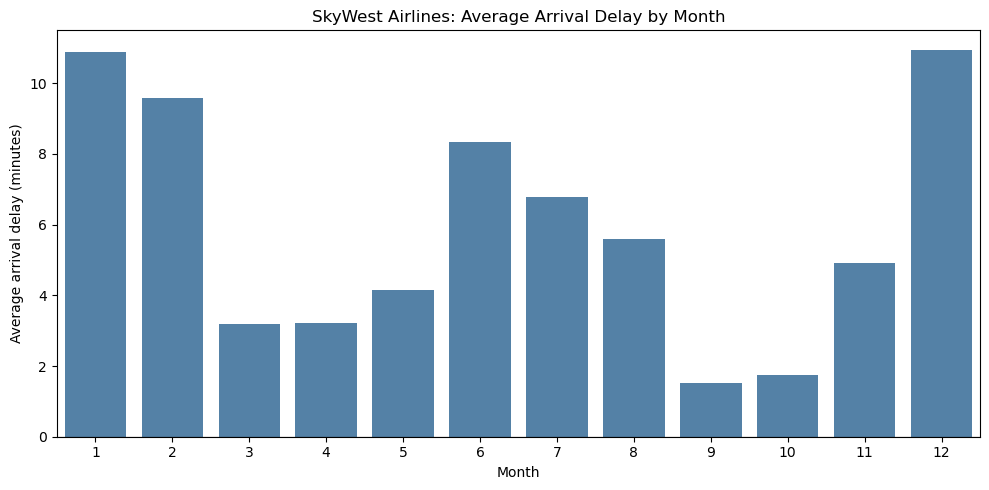

In [5]:
plt.figure(figsize=(10, 5))
sns.barplot(x=flight_delay.index, y=flight_delay["OO"], color="steelblue")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("SkyWest Airlines: Average Arrival Delay by Month")
plt.xlabel("Month")
plt.ylabel("Average arrival delay (minutes)")
plt.tight_layout()
plt.show()


## Heatmap
We create a heatmap to quickly visualize patterns for all airlines for all months in the DataFrame using Seaborn `sns.heatmap()` Each cell is color-coded according to its corresponding value.  

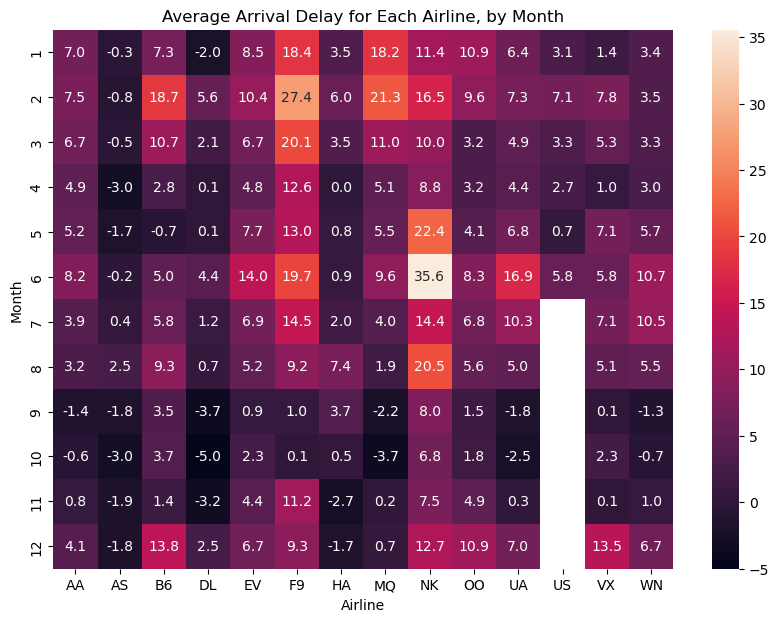

In [6]:
### Heatmap showing average arrival delay for each airline by month
plt.figure(figsize=(10, 7))
sns.heatmap(data=flight_delay, annot=True, fmt=".1f")
plt.title("Average Arrival Delay for Each Airline, by Month")
plt.xlabel("Airline");


### Colormaps
You can set the `cmap` argument to select a specific colormap to apply to your heatmap. There are many different colormaps to choose from.
https://matplotlib.org/3.1.0/gallery/color/colormap_reference.html

### Annotate
The parameter `annot=True` ensures that the values for each cell appear on the chart. If we were to leave out this parameter, it will remove the numbers from each of the cells.

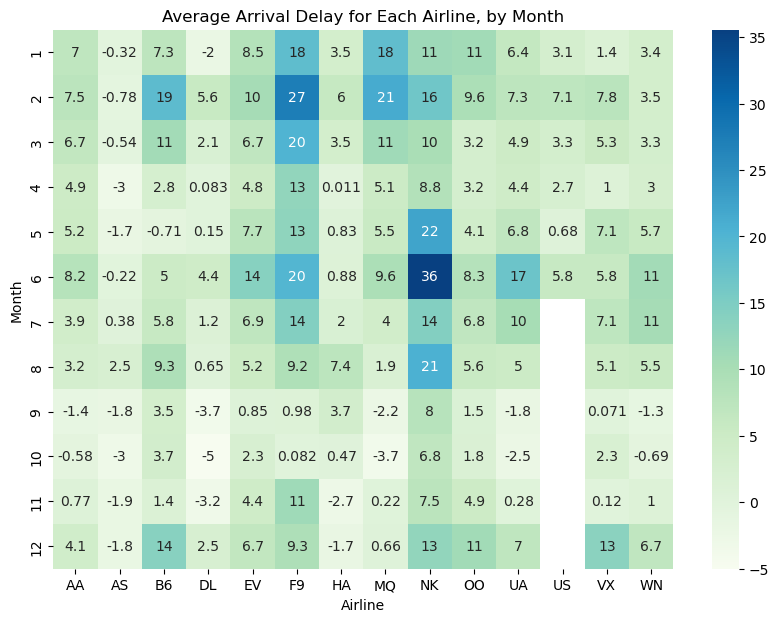

In [7]:
### Heatmap showing average arrival delay for each airline by month
## Use cmap='GnBu' to change the colors for the heatmap
plt.figure(figsize=(10,7))
sns.heatmap(data=flight_delay,
            annot=True, #annotation of cells
            cmap="GnBu" #colormap
           )

plt.title("Average Arrival Delay for Each Airline, by Month")
plt.xlabel("Airline");

### Fill in the missing data
We can use dataframe's `fillna` method to replace all the NaN to zero. Use `inplace=True`.

Something to note is that filling in zero may be misleading because missing means unobserved/unknown while zero means no average delay. Filling with zero make those meaning indistinguishable.

In [8]:
flight_delay.fillna(0, inplace=True)

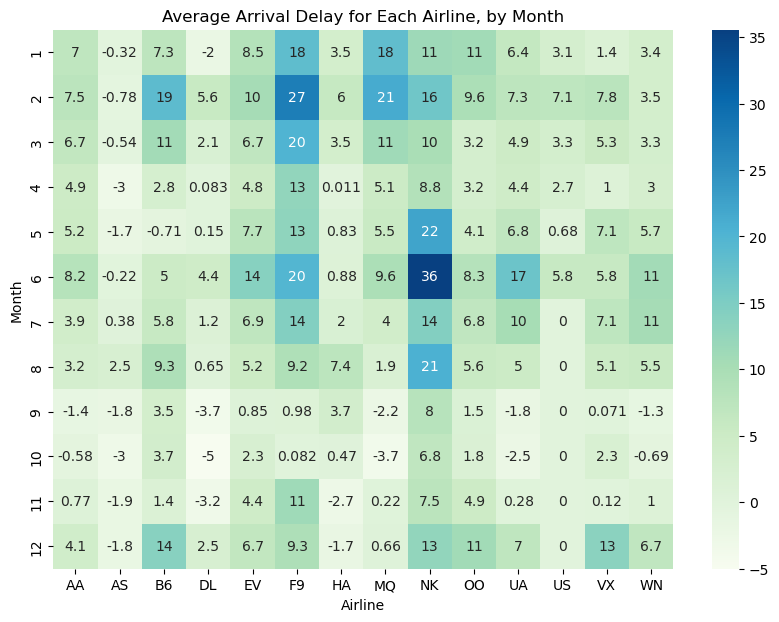

In [9]:
### Heatmap with annotation and colormap
plt.figure(figsize=(10,7))
sns.heatmap(data=flight_delay,
            annot=True,
            cmap="GnBu"
           )

plt.title("Average Arrival Delay for Each Airline, by Month")
plt.xlabel("Airline");

### `map()` on Series
Let's say we want to point out which airline and which month has over 15 minute delayed arrivals. We can make an annotation table that simply indicates which cells have a value that is greater than 15. One  way to do this is using `map()`.

In [10]:
def classify_cell(value):
  '''Run a function on each cell of the count summary individually'''
  if value > 15:
    return str(round(value, 2))
  else:
    return ""

## Table with only values >15
annotation_table = flight_delay.map(classify_cell)
annotation_table

,AA,AS,B6,DL,EV,F9,HA,MQ,NK,OO,UA,US,VX,WN
Month,,,,,,,,,,,,,,
1,,,,,,18.36,,18.16,,,,,,
2,,,18.66,,,27.42,,21.3,16.47,,,,,
3,,,,,,20.07,,,,,,,,
4,,,,,,,,,,,,,,
5,,,,,,,,,22.4,,,,,
6,,,,,,19.71,,,35.56,,16.93,,,
7,,,,,,,,,,,,,,
8,,,,,,,,,20.52,,,,,
9,,,,,,,,,,,,,,


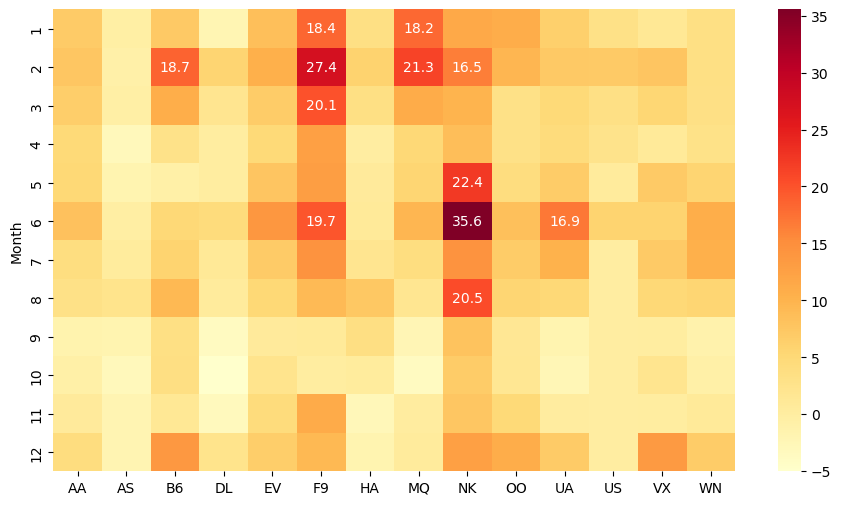

In [11]:
### Alternative method to run the annotation
labels = flight_delay.apply(lambda col: col.map(lambda x: f'{x:.1f}' if pd.notna(x) and x>15 else ''))
plt.figure(figsize=(11,6))
sns.heatmap(flight_delay,annot=labels,fmt='',cmap='YlOrRd')
plt.show()

### Annotation
We can change the annotation to use the table we generated above using `annot=`. To using the annotation table we also have to include the parameter `fmt="s"` for the annot to recognize the strong format.

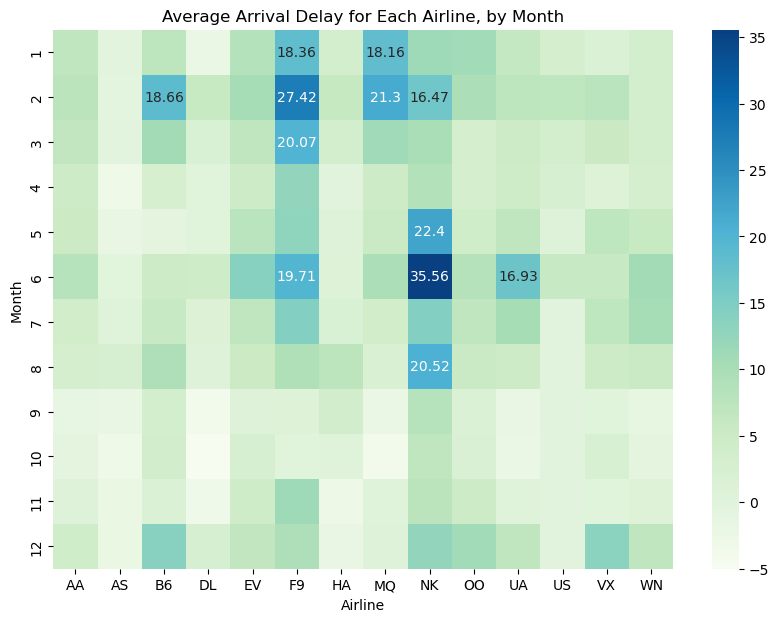

In [12]:
### Heatmap showing average arrival delay for each airline by month.
plt.figure(figsize=(10,7))
sns.heatmap(data=flight_delay,
            cmap="GnBu",
            annot=annotation_table, #our defined table
            fmt="s" #string format
           )

plt.title("Average Arrival Delay for Each Airline, by Month")
plt.xlabel("Airline");

### CL13.3 Counts
Count how many months each airline has averge delay >15 minutes. Explain why is this value not the same as the number of delayed flights?

In [13]:
months_over_15 = (
    flight_delay.gt(15)
    .sum(axis=0)
    .sort_values(ascending=False)
    .rename("Months with average arrival delay > 15 minutes")
)
months_over_15.to_frame()


,Months with average arrival delay > 15 minutes
F9,4
NK,4
MQ,2
B6,1
UA,1
AA,0
AS,0
DL,0
EV,0
HA,0


**CL13.3 explanation:** Frontier (F9) and Spirit (NK) each have 4 months
with an average arrival delay above 15 minutes; Envoy (MQ) has 2;
JetBlue (B6) and United (UA) each have 1. The other airlines have 0.
Each table cell summarizes an airline's monthly average, so this counts
**months**, not individual delayed flights. A monthly average cannot
tell us how many flights were delayed or how many flights operated.
The earlier replacement of missing values with zero also means that
an unobserved month does not count toward this threshold.


### Heatmaps with many categories
Our examples above have a relatively small number of categories on each axis. When we see a particularly bright or dark cell we can, with a bit of effort, look at the axis labels to determine which category it belongs to.
  
What happens when we try to display more data? For example if we were to look at the mean daily temperature dataset.

In [14]:
weather_data = "https://raw.githubusercontent.com/csbfx/advpy122-data/master/weather.csv"
weather = pd.read_csv(weather_data)
weather

,City,Year,Month,Day of year,Day of month,Mean temperature
0,Berlin,1960,January,1,1,6.4
1,Berlin,1960,January,2,2,8.1
2,Berlin,1960,January,3,3,5.4
3,Berlin,1960,January,4,4,3.9
4,Berlin,1960,January,5,5,6.0
...,...,...,...,...,...,...
63711,London,2018,October,300,27,4.9
63712,London,2018,October,301,28,7.4
63713,London,2018,October,302,29,5.8
63714,London,2018,October,303,30,6.6


We will begin by trying to visualize the complete weather data for a single city. Filter to find the rows for the city Berlin, then construct a summary table by putting "Year" as the index and "Day of year" as the column names via `groupby()`.   
Lastly `unstack()` to reshape data from a "long" format to a "wide" format; take the first value encountered `first()` for each resulting cell.

In [15]:
berlin_summary=(
    weather[weather["City"]=="Berlin"].groupby(["Year", "Day of year"])["Mean temperature"].first().unstack()
    )
berlin_summary

Day of year,1,2,3,4,5,6,7,8,9,10,...,357,358,359,360,361,362,363,364,365,366
Year,,,,,,,,,,,,,,,,,,,,,
1960,6.4,8.1,5.4,3.9,6.0,4.0,3.5,0.9,-3.9,-4.8,...,1.8,1.8,0.4,-0.6,2.5,1.8,1.2,1.2,0.2,-0.3
1961,1.5,0.4,3.5,2.4,2.2,1.7,1.6,2.6,3.0,2.5,...,-6.2,-8.4,-12.5,-12.8,-9.2,-9.2,-1.5,1.2,2.7,NaN
1962,2.1,-1.6,0.0,-1.1,-3.3,1.6,1.7,3.2,3.4,3.6,...,-8.7,-7.1,-6.8,-8.3,-7.4,-5.6,-7.2,-6.1,-7.4,NaN
1963,-12.7,-10.5,-7.4,-2.6,1.3,-2.2,-3.4,-7.4,-9.5,-11.8,...,-9.0,-7.6,-4.7,2.4,2.7,1.3,0.6,2.7,-0.4,NaN
1964,2.5,4.0,1.0,-1.0,-2.6,0.3,1.0,1.1,-0.8,-5.5,...,-0.6,-1.8,-3.8,-4.2,-4.3,-5.8,-3.6,-3.0,-1.4,7.0
1965,4.8,2.9,1.8,-0.3,2.9,0.8,-0.5,6.0,3.6,0.6,...,1.1,3.5,5.3,3.2,1.2,-0.4,0.5,1.6,3.8,NaN
1966,5.2,6.4,2.8,-3.7,-4.4,-6.0,-2.5,-3.0,-4.6,-4.5,...,2.6,1.9,0.4,0.2,-0.3,1.0,4.0,5.9,4.2,NaN
1967,3.1,2.7,0.8,-0.7,-1.6,-2.8,-2.8,-8.8,-10.6,-7.8,...,8.9,7.3,5.9,2.4,-1.4,1.4,1.8,-1.2,0.1,NaN
1968,-0.5,-2.0,-1.1,-1.4,-1.4,-4.4,-7.4,-5.5,-9.0,-10.2,...,2.8,4.7,0.8,0.8,0.1,-1.4,-3.2,-5.1,-5.7,-3.9


To plot the data we’ll pass our summary table to heatmap with a generous size and choose a colur palette that fits
with the theme of temperature:

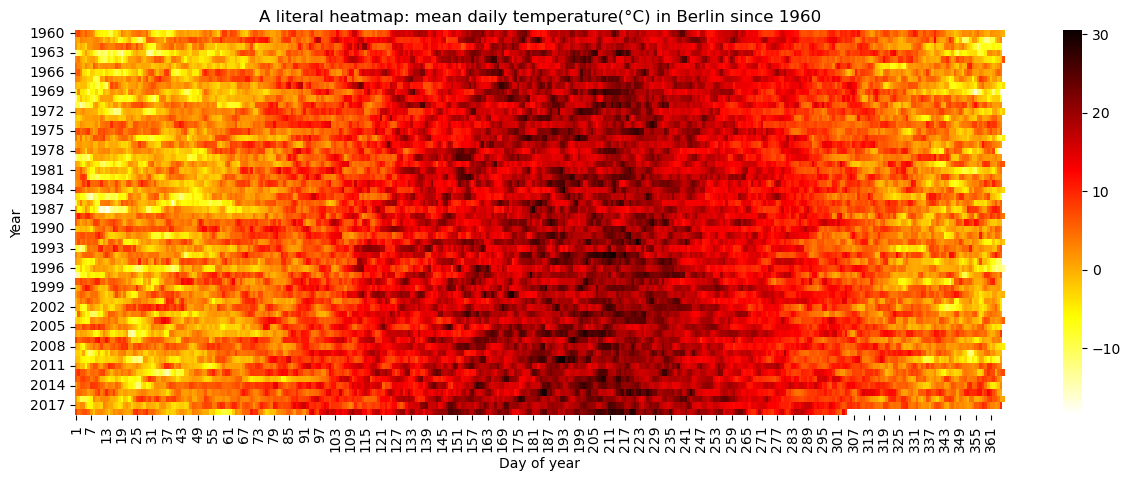

In [16]:
plt.figure(figsize=(15,5))

sns.heatmap(berlin_summary,
            cmap="hot_r")

plt.title(
    "A literal heatmap: mean daily temperature(°C) in Berlin since 1960"
);

Note some interesting pattern in the data are the leap years; day 366 is missing for non-leap years. And the data for 2018 are missing for the last part of the year, as this dataset ends halfway through that year.


## Diverging palettes with heatmaps
When there is a natural center point for our data, we can often make good use of a diverging palette to add more context to the data. `diverging_palette()` can be use to highlight how data points deviate (diverge). For temperature, we might pick freezing point - 0 degrees in our dataset, which is measured in Celcius - as the center point.

You can choose your paletter interactively by calling seaborn's `choose_diverging_palette()` method to help determine the arguments.

`seaborn.diverging_palette(h_neg, h_pos, s=75, l=50, sep=1, n=6, center='light', as_cmap=False)`

[Parameters](https://seaborn.pydata.org/generated/seaborn.diverging_palette.html)
- `h_neg`, `h_pos`: float in [0, 359]
    - Anchor hues for negative and positive extents of the map.
- `s`: float in [0, 100], optional
    - Anchor saturation for both extents of the map.
- `l`: float in [0, 100], optional
    - Anchor lightness for both extents of the map.
- `sep`: int, optional
    - Size of the intermediate region.
- `n`: int, optional
    - Number of colors in the palette (if not returning a cmap)
- `center`: {"light", "dark"}, optional
    - Whether the center of the palette is light or dark
- `as_cmap`: bool, optional
    - If True, return a matplotlib.colors.Colormap.

#### Returns
- list of RGB tuples or matplotlib.colors.Colormap

In [17]:
# sns.choose_diverging_palette()

If we pick a `diverging_palette` and set the `center=` argument, we get this view of the data:

In [18]:
### Use custom color map
cmap = sns.diverging_palette(316, 133, 95, 47, 10, 15, center="light", as_cmap=True)
# cmap = sns.diverging_palette(232, 0, 83, 68, 30, 16, center="dark", as_cmap=True)
# cmap = sns.diverging_palette(196, 291, 61, 75, 21, 15, center="light", as_cmap=True)

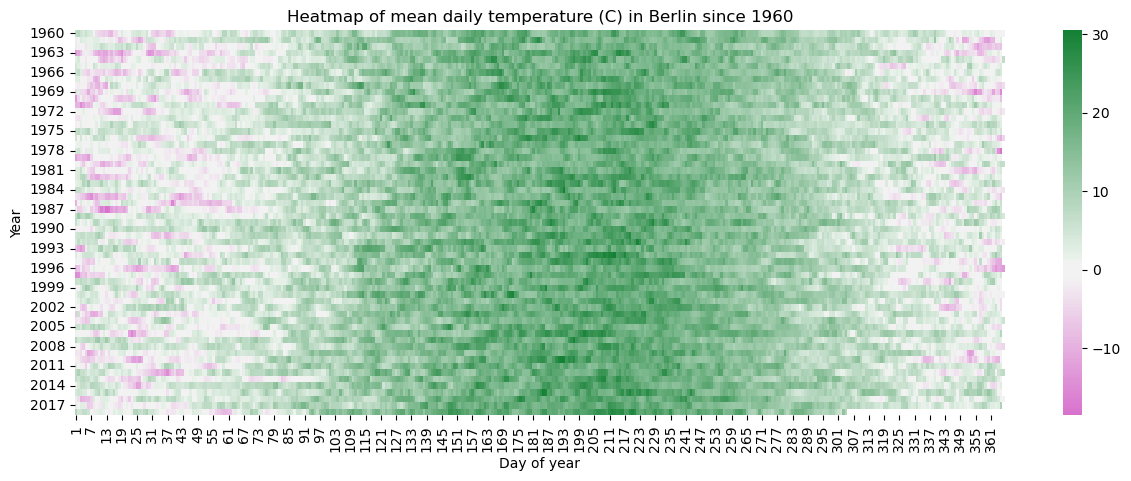

In [19]:
plt.figure(figsize=(15, 5))
sns.heatmap(berlin_summary, cmap=cmap, center=0)
plt.title("Heatmap of mean daily temperature (C) in Berlin since 1960");


### Working with summary tables
For our final look at the temperature data, we will take a 10-year span and try to visualize the temperature in all three cities. To build our summary table we first have to filter by year, then include city in our grouping.

### CL13.4 Build a summary table
Above we built a summary table looking only at Berlin's mean temperature by Year and Day of Year.  

Let's build another summary table but this time we want to consider only Year between 1980 and 1990 via using the parameter `between(min, max)`. Group those years by "City", "Days of Year", and "Year" and return the "Mean temperature". Afterwards, use `.first` to get the first value from your aggregated table.




In [20]:
# between includes both endpoints: 1980 through 1990.
city_dayofyear = (
    weather.loc[weather["Year"].between(1980, 1990)]
    .groupby(["City", "Day of year", "Year"])["Mean temperature"]
)
city_dayofyear.first()


City    Day of year  Year
Berlin  1            1980    0.8
                     1981    3.1
                     1982    3.1
                     1983    1.9
                     1984    6.9
                            ... 
London  365          1989    3.8
                     1990    6.8
        366          1980    9.2
                     1984    7.1
                     1988    7.2
Name: Mean temperature, Length: 12054, dtype: float64

In [21]:
# # Example code
# ### Group the weather by City, Days of Year, and Year
# city_dayofyear = weather[weather["Year"].between(1980, 1990)].groupby(["City","Day of year","Year"])["Mean temperature"]

# ## Taking the first value from the aggregate
# city_dayofyear.first()

In [22]:
### Turning the Series into a wide dataframe
city_dayofyear.first().unstack()

Year                1980  1981  1982  1983  1984  1985  1986  1987  1988  \
City   Day of year                                                         
Berlin 1             0.8   3.1   3.1   1.9   6.9  -3.2  -9.6   1.7   6.9   
       2            -0.5   3.2   3.7   3.0   6.2  -4.2  -1.6  -5.9  11.2   
       3            -3.5   6.3   8.0   3.6   5.7  -6.3   3.8  -5.6   8.2   
       4            -6.5   2.3   8.7   8.5   3.9  -7.2  -1.5  -3.1   6.9   
       5            -2.3  -0.2   6.8   6.4   1.2 -10.1  -1.0   2.1   9.3   
...                  ...   ...   ...   ...   ...   ...   ...   ...   ...   
London 362           2.0   2.6   4.0  11.2   2.2  -3.3   6.4  12.1   8.9   
       363           3.4   6.8   4.2   7.5   1.7  -2.4   9.1  12.4  10.0   
       364           6.2   6.9   6.0   5.7   2.0  -0.5  10.2  10.0   7.9   
       365           9.0   6.0   5.4   5.6   2.8   0.0   8.9   9.8   7.4   
       366           9.2   NaN   NaN   NaN   7.1   NaN   NaN   NaN   7.2   

Year                1989  1990  
City   Day of year              
Berlin 1             6.2  -1.7  
       2             2.6  -1.4  
       3             0.3  -0.4  
       4             2.1  -1.4  
       5             3.5  -0.2  
...                  ...   ...  
London 362           6.5   7.5  
       363           5.0   7.5  
       364           4.4   6.3  
       365           3.8   6.8  
       366           NaN   NaN  

[1098 rows x 11 columns]

In [23]:
### Further widening dataframe by using multiple unstack()
city_dayofyear.first().unstack().unstack()


Year        1980                                               ... 1990       \
Day of year  1    2    3    4    5    6    7    8    9    10   ...  357  358   
City                                                           ...             
Berlin       0.8 -0.5 -3.5 -6.5 -2.3 -0.2 -2.7 -4.6 -5.4 -5.2  ...  3.6 -0.2   
Edinburgh   -2.0 -2.1  2.0  3.8  6.0  5.8  4.9  2.2  0.8  1.6  ...  6.6  4.9   
London      -1.8 -1.8  2.6  5.2  4.8  5.8  5.2  3.8  2.6  2.7  ...  9.2  8.8   

Year                                                
Day of year  359  360  361  362  363  364  365 366  
City                                                
Berlin      -1.1  1.3  4.5  2.7  6.8  5.8  3.4 NaN  
Edinburgh    5.0  5.7  3.0  3.5  1.4  2.2  3.3 NaN  
London       6.6  8.2  5.8  7.5  7.5  6.3  6.8 NaN  

[3 rows x 4026 columns]

In [24]:
### The steps we took above to get 10 years worth of temperature for Cities
ten_years=(
    weather[weather["Year"].between(1980, 1990)]
    .groupby(["City","Day of year","Year"])["Mean temperature"]
    .first()
    .unstack()
    .unstack()
)

In [25]:
ten_years

Year        1980                                               ... 1990       \
Day of year  1    2    3    4    5    6    7    8    9    10   ...  357  358   
City                                                           ...             
Berlin       0.8 -0.5 -3.5 -6.5 -2.3 -0.2 -2.7 -4.6 -5.4 -5.2  ...  3.6 -0.2   
Edinburgh   -2.0 -2.1  2.0  3.8  6.0  5.8  4.9  2.2  0.8  1.6  ...  6.6  4.9   
London      -1.8 -1.8  2.6  5.2  4.8  5.8  5.2  3.8  2.6  2.7  ...  9.2  8.8   

Year                                                
Day of year  359  360  361  362  363  364  365 366  
City                                                
Berlin      -1.1  1.3  4.5  2.7  6.8  5.8  3.4 NaN  
Edinburgh    5.0  5.7  3.0  3.5  1.4  2.2  3.3 NaN  
London       6.6  8.2  5.8  7.5  7.5  6.3  6.8 NaN  

[3 rows x 4026 columns]

### CL13.5 Construct the table using pivot_table instead

An alternative to using the `groupby().first().unstack()` approach is to use pivot_table(). Rebuild the ten year summary that consider City x [Year, Day of Year] temperature matrix for dates between 1980 and 1990.  


In [26]:
ten_years_pivot = weather.loc[weather["Year"].between(1980, 1990)].pivot_table(
    index="City",
    columns=["Year", "Day of year"],
    values="Mean temperature",
    aggfunc="first",
    dropna=False,
)
# Keep missing combinations, such as day 366 in a non-leap year,
# to match the groupby/first/unstack result.
pd.testing.assert_frame_equal(ten_years_pivot, ten_years)
ten_years_pivot


Year        1980                                               ... 1990       \
Day of year  1    2    3    4    5    6    7    8    9    10   ...  357  358   
City                                                           ...             
Berlin       0.8 -0.5 -3.5 -6.5 -2.3 -0.2 -2.7 -4.6 -5.4 -5.2  ...  3.6 -0.2   
Edinburgh   -2.0 -2.1  2.0  3.8  6.0  5.8  4.9  2.2  0.8  1.6  ...  6.6  4.9   
London      -1.8 -1.8  2.6  5.2  4.8  5.8  5.2  3.8  2.6  2.7  ...  9.2  8.8   

Year                                                
Day of year  359  360  361  362  363  364  365 366  
City                                                
Berlin      -1.1  1.3  4.5  2.7  6.8  5.8  3.4 NaN  
Edinburgh    5.0  5.7  3.0  3.5  1.4  2.2  3.3 NaN  
London       6.6  8.2  5.8  7.5  7.5  6.3  6.8 NaN  

[3 rows x 4026 columns]

**CL13.5 note:** `between(1980, 1990)` includes both endpoints, so the
requested bounds cover **11 calendar years**, despite the exercise's
"ten year" wording. Both methods use the same inclusive range and
preserve unavailable temperatures as missing values.


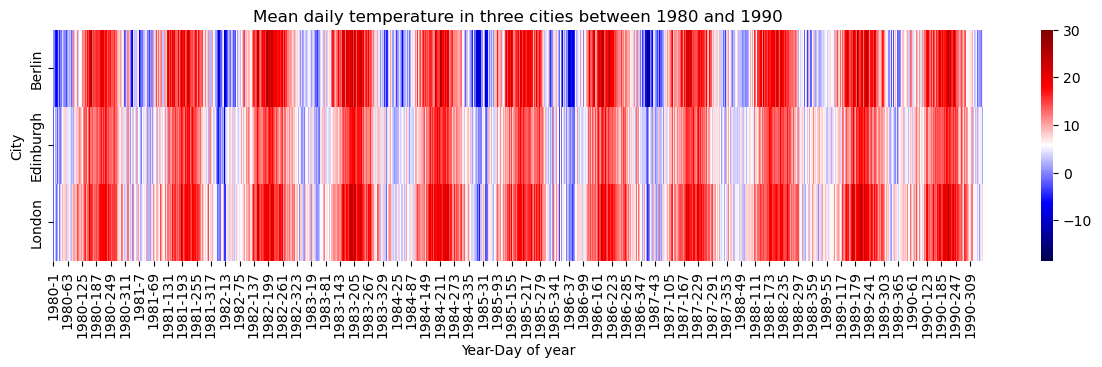

In [27]:
### Plot the heatmap
plt.figure(figsize=(15,3))
sns.heatmap(ten_years, cmap="seismic")
plt.title("Mean daily temperature in three cities between 1980 and 1990");

## Clustermaps
Closely related to the heatmap is the clustermap. To understand how clustermaps work, imagine treating every column as a vector of values and calculating the distance to every other column (can do it for rows as well). This gives us a distance matrix. We can then take this distance matrix and use a clustering algorithm to create a tree (technically a dendrogram) showing which groups of columns are most similar.

We will want to remove years with missing data using `dropna(axis=1)`.

In [28]:
city_summary = (
    weather.groupby(["City","Year"])
    ["Mean temperature"]
    .mean().unstack().dropna(axis=1)
)
city_summary

Year,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,...,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
City,,,,,,,,,,,,,,,,,,,,,
Berlin,9.366120,9.829041,8.222192,8.628493,9.127049,8.604384,9.489315,10.326575,9.480328,8.70411,...,10.934247,10.751093,10.312055,8.946301,10.832055,10.240437,9.902740,11.485205,11.290685,10.832787
Edinburgh,8.916944,9.002192,8.158333,7.812813,8.695082,7.963014,8.410959,8.958082,8.401366,8.39589,...,9.924932,9.456011,9.697260,8.541370,10.040000,9.112568,9.489589,10.369041,9.601918,9.541530
London,10.617760,10.989041,9.396712,9.359178,10.445355,9.882740,10.461370,10.564110,10.268579,10.57863,...,11.942192,11.380328,11.752603,10.635890,12.378082,11.329781,11.164110,12.660000,12.137260,11.919126


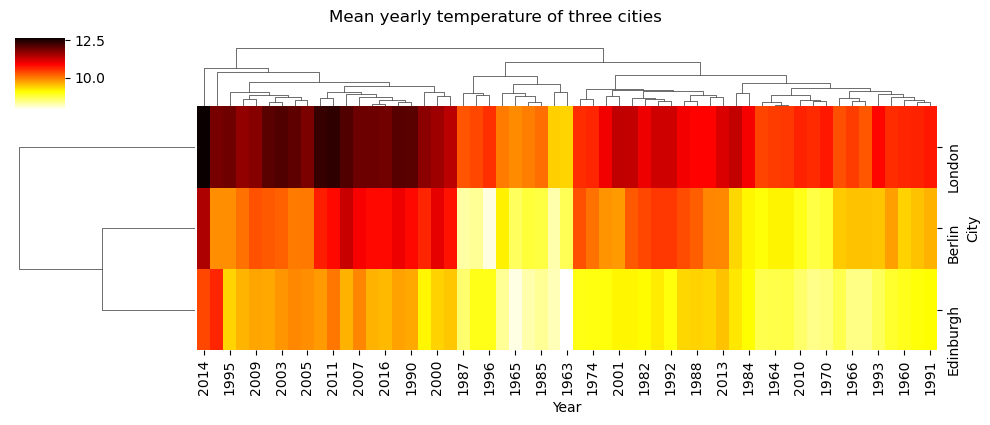

In [29]:
### Clustermap where both rows (default True) and column are clustered
g = sns.clustermap(
    city_summary, cmap="hot_r",figsize=(10,4)
    )
g.fig.suptitle("Mean yearly temperature of three cities",y=1.05);

The dendrogram reinforces the pattern that’s apparent from the colors in the data: Edinburgh and Berlin are more similar, with London generally warmer. Although `heatmap` and `clustermap` are closely related, their return values are slightly different types. `heatmap` returns a maplotlib `Axes` object, whereas `clustermap` returns a seaborn `ClusterGrid` object. The only real significance of this is that to add a title for a clustermap we need to use the
`g.fig.suptitle` just like we did with `relplot`.

Above we see that both rows and column clustered. The dendrogram on top of the heatmap is showing us which years were most similar, which might be interesting for some datasets but is confusing here, as it reorders the years so that they are not in chronological order any more.
  
If we want to only cluster the row, we can omit the clustering of columns by passing `col_cluster=False`.

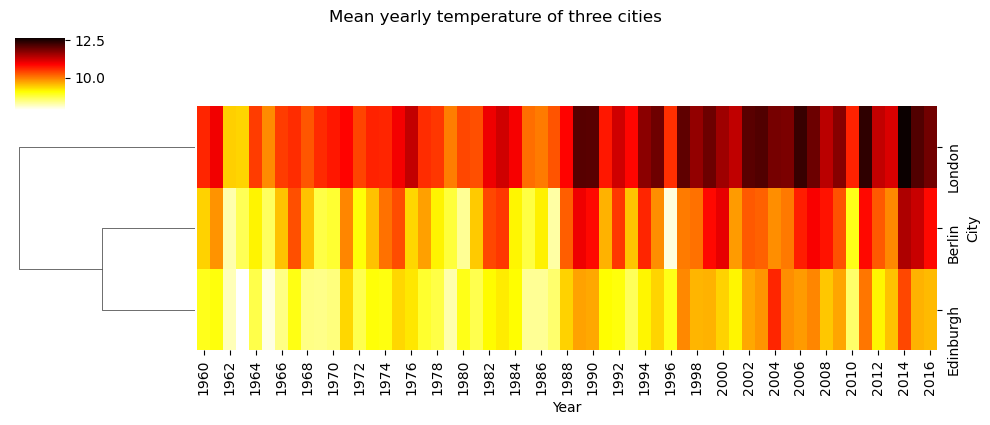

In [30]:
g = sns.clustermap(
    city_summary,
    col_cluster=False,
    cmap="hot_r",
    figsize=(10,4)
    )
g.fig.suptitle("Mean yearly temperature of three cities", y=1.05);

## Complex groups with clustermaps

In [31]:
fungi_genomes = "https://raw.githubusercontent.com/csbfx/advpy122-data/master/fungi_genomes.csv"
genomes = pd.read_csv(fungi_genomes)
genomes

,species,Class,AAAAAA,AAAAAT,AAAAAG,AAAAAC,AAAATA,AAAATT,AAAATG,AAAATC,...,CCCCTG,CCCCTC,CCCCGA,CCCCGT,CCCCGG,CCCCGC,CCCCCA,CCCCCT,CCCCCG,CCCCCC
0,Schizosaccharomyces octosporus,Ascomycetes,0.002445,0.001331,0.001211,0.000814,0.001132,0.001058,0.000757,0.000699,...,0.000039,0.000059,0.000050,0.000047,0.000025,0.000018,0.000055,0.000047,0.000027,0.000029
1,Coniosporium apollinis,Ascomycetes,0.000194,0.000155,0.000237,0.000165,0.000229,0.000136,0.000144,0.000182,...,0.000151,0.000317,0.000165,0.000145,0.000145,0.000242,0.000205,0.000201,0.000157,0.000172
2,Phialophora attae,Ascomycetes,0.000061,0.000088,0.000150,0.000080,0.000087,0.000113,0.000175,0.000169,...,0.000133,0.000186,0.000141,0.000100,0.000104,0.000123,0.000114,0.000081,0.000073,0.000041
3,Nannizzia gypsea,Ascomycetes,0.000833,0.000365,0.000620,0.000309,0.000394,0.000253,0.000324,0.000263,...,0.000239,0.000182,0.000151,0.000159,0.000146,0.000113,0.000191,0.000223,0.000130,0.000167
4,Trichoderma asperellum,Ascomycetes,0.002215,0.000708,0.000729,0.000368,0.000795,0.000504,0.000364,0.000327,...,0.000179,0.000240,0.000144,0.000131,0.000124,0.000147,0.000201,0.000210,0.000126,0.000272
5,Zymoseptoria tritici,Ascomycetes,0.000114,0.000102,0.000203,0.000118,0.000105,0.000115,0.000161,0.000179,...,0.000091,0.000217,0.000148,0.000087,0.000103,0.000123,0.000084,0.000117,0.000080,0.000082
6,Cladophialophora immunda,Ascomycetes,0.000231,0.000166,0.000290,0.000162,0.000166,0.000157,0.000269,0.000244,...,0.000213,0.000278,0.000237,0.000193,0.000209,0.000181,0.000238,0.000222,0.000183,0.000264
7,Pestalotiopsis fici,Ascomycetes,0.001234,0.000539,0.000579,0.000315,0.000573,0.000427,0.000357,0.000335,...,0.000158,0.000203,0.000186,0.000133,0.000162,0.000142,0.000209,0.000158,0.000136,0.000208
8,Pseudogymnoascus verrucosus,Ascomycetes,0.000416,0.000302,0.000293,0.000270,0.000348,0.000221,0.000300,0.000299,...,0.000196,0.000539,0.000221,0.000189,0.000154,0.000344,0.000412,0.000410,0.000240,0.000649
9,Bipolaris sorokiniana,Ascomycetes,0.000625,0.000268,0.000434,0.000302,0.000272,0.000195,0.000268,0.000259,...,0.000134,0.000267,0.000140,0.000127,0.000110,0.000218,0.000235,0.000196,0.000140,0.000257


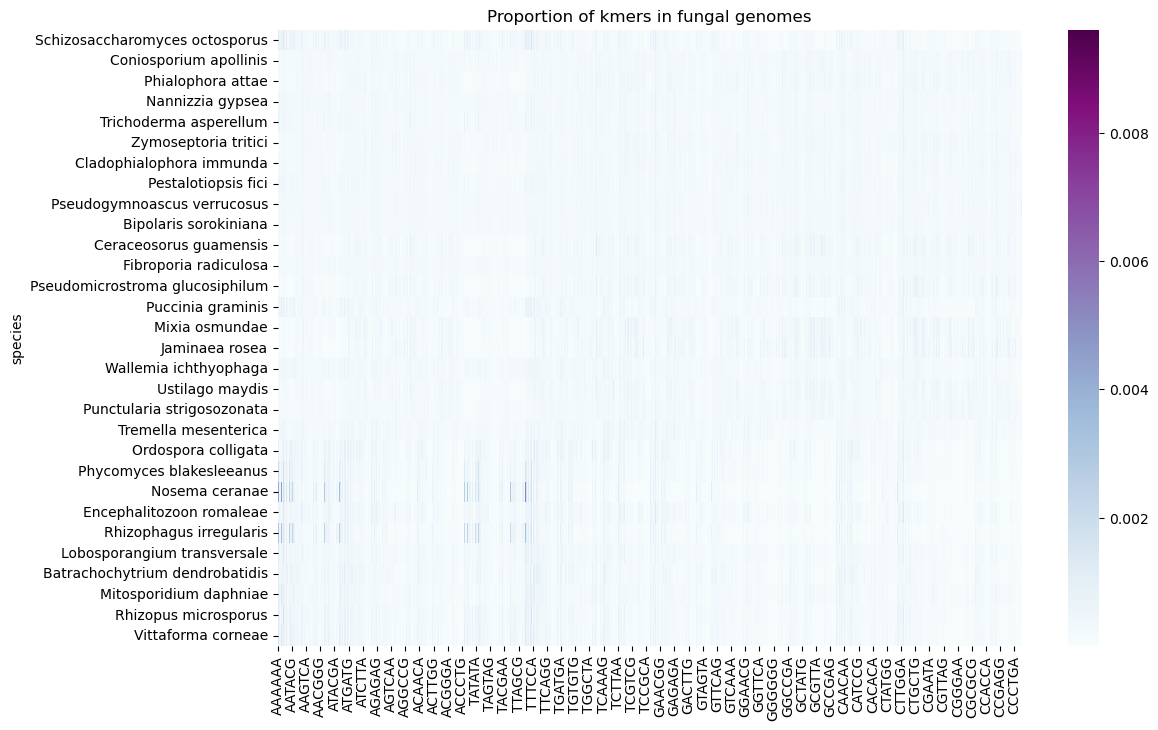

In [32]:
### Plot clustermap of species and kmers
plt.figure(figsize=(12,8))
sns.heatmap(genomes.set_index("species").drop(columns=["Class"]),
            cmap="BuPu")
plt.title("Proportion of kmers in fungal genomes");

In the figure, we can see a common problem with these kind of data; we have a small number of outliers with very high proportions that are determining the color scale and making it hard to see the patterns. We will manually set the axis limits, we can set the color scale limit with `vmax`. `vmax` changes color mapping/saturation, not the underlying data. Very high values share the saturated color.

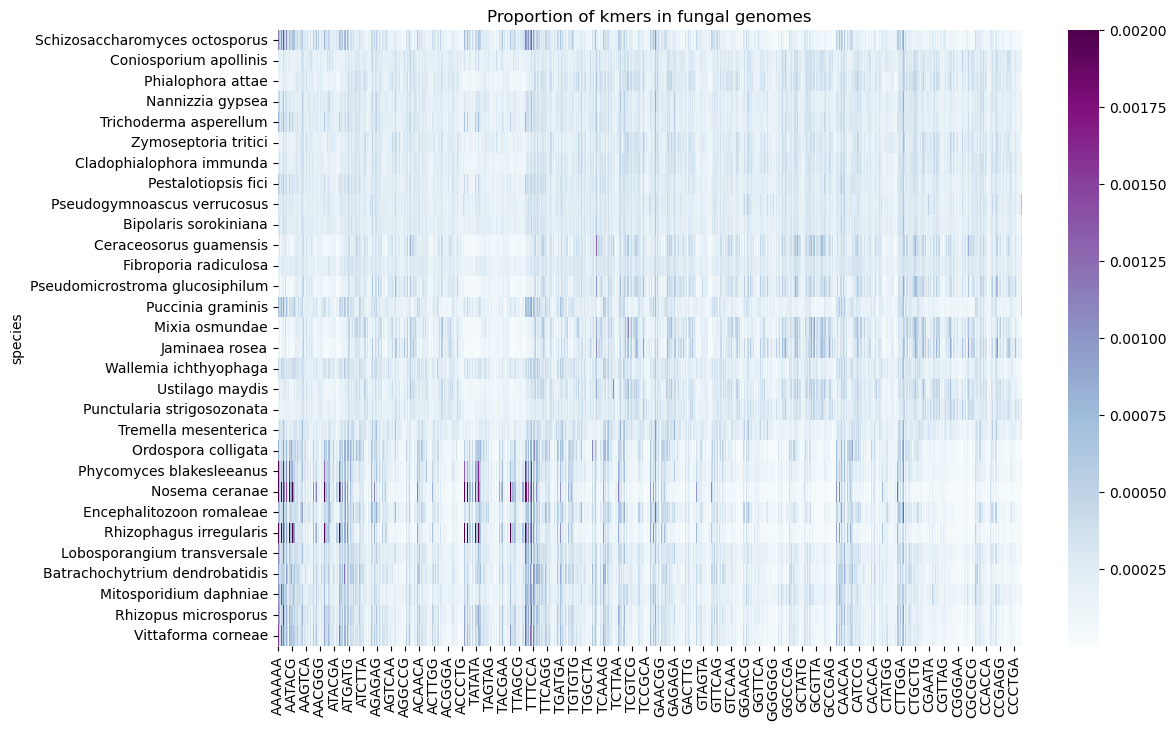

In [33]:
plt.figure(figsize=(12,8))
sns.heatmap(
    genomes.set_index("species").drop(columns=["Class"]),
    cmap="BuPu",
    vmax=0.002)
plt.title("Proportion of kmers in fungal genomes");

<Axes: >

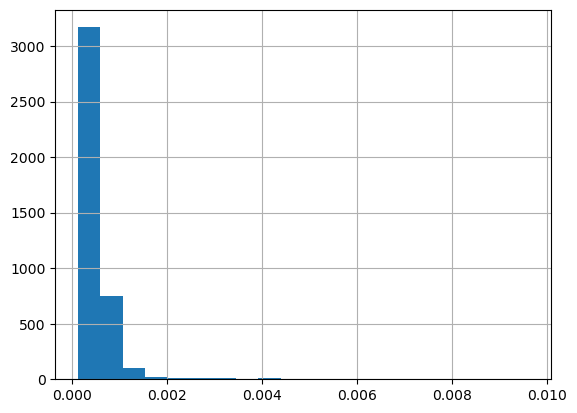

In [34]:
genomes.drop(columns=["species", "Class"]).max().hist(bins=20)

With over four thousand data points on the horizontal axis there are way too many to label them all, but seaborn draws as many labels as will fit in the space available. This makes things clearer to see. There are definitely patterns in the distribution of 6mer counts, but it’s very difficult for us to summarize. Let’s get seaborn to do the clustering by switching to `clustermap`:

C:\Users\hurri\anaconda3\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


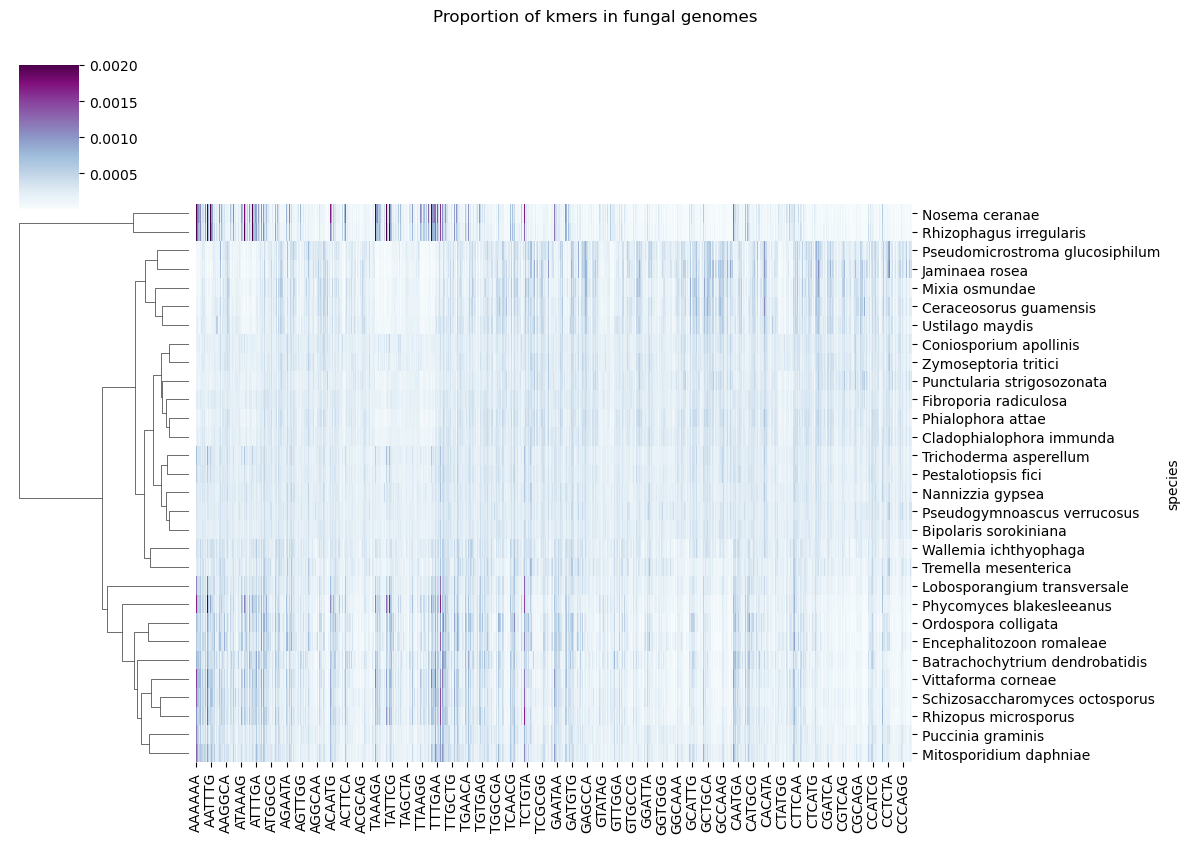

In [35]:
g=sns.clustermap(
    genomes.set_index("species").drop(columns=["Class"]),
    cmap="BuPu",
    vmax=0.002,
    col_cluster=False,
    figsize=(12,8),
)
g.fig.suptitle("Proportion of kmers in fungal genomes", y=1.05);

Notice the slight difference in the way we set the size: clustermap has its own figsize argument so we don’t need to use plt.figure.

The dendrogram shows some nicely defined clusters of genomes that have similar patterns. However, the dendrogram is on the opposite side from the species names, it’s hard to see which species belong to which clusters. And unless we are very familiar with fungal taxonomy, the species names don’t actually tell us what class each one belongs to.

There’s one final feature of clustermaps that will help us address both these problems. We can add a column of colors to annotate the dendrogram by passing a `row_colors` argument which contains a series mapping the labels (in our case, species names) to the colors we want. The easiest way to create this list is to start with the list of classes and simply replace the class names with the colors that we want:

In [36]:
# Create a series of colors corresponding to the class names
class_color=genomes.set_index("species")["Class"].replace({"Ascomycetes":"red","Basidiomycetes":"purple","Other Fungi":"lightblue"})
class_color

species
Schizosaccharomyces octosporus           red
Coniosporium apollinis                   red
Phialophora attae                        red
Nannizzia gypsea                         red
Trichoderma asperellum                   red
Zymoseptoria tritici                     red
Cladophialophora immunda                 red
Pestalotiopsis fici                      red
Pseudogymnoascus verrucosus              red
Bipolaris sorokiniana                    red
Ceraceosorus guamensis                purple
Fibroporia radiculosa                 purple
Pseudomicrostroma glucosiphilum       purple
Puccinia graminis                     purple
Mixia osmundae                        purple
Jaminaea rosea                        purple
Wallemia ichthyophaga                 purple
Ustilago maydis                       purple
Punctularia strigosozonata            purple
Tremella mesenterica                  purple
Ordospora colligata                lightblue
Phycomyces blakesleeanus           lightblue
No

Now we can add these colors to our clustermap.

C:\Users\hurri\anaconda3\Lib\site-packages\seaborn\matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


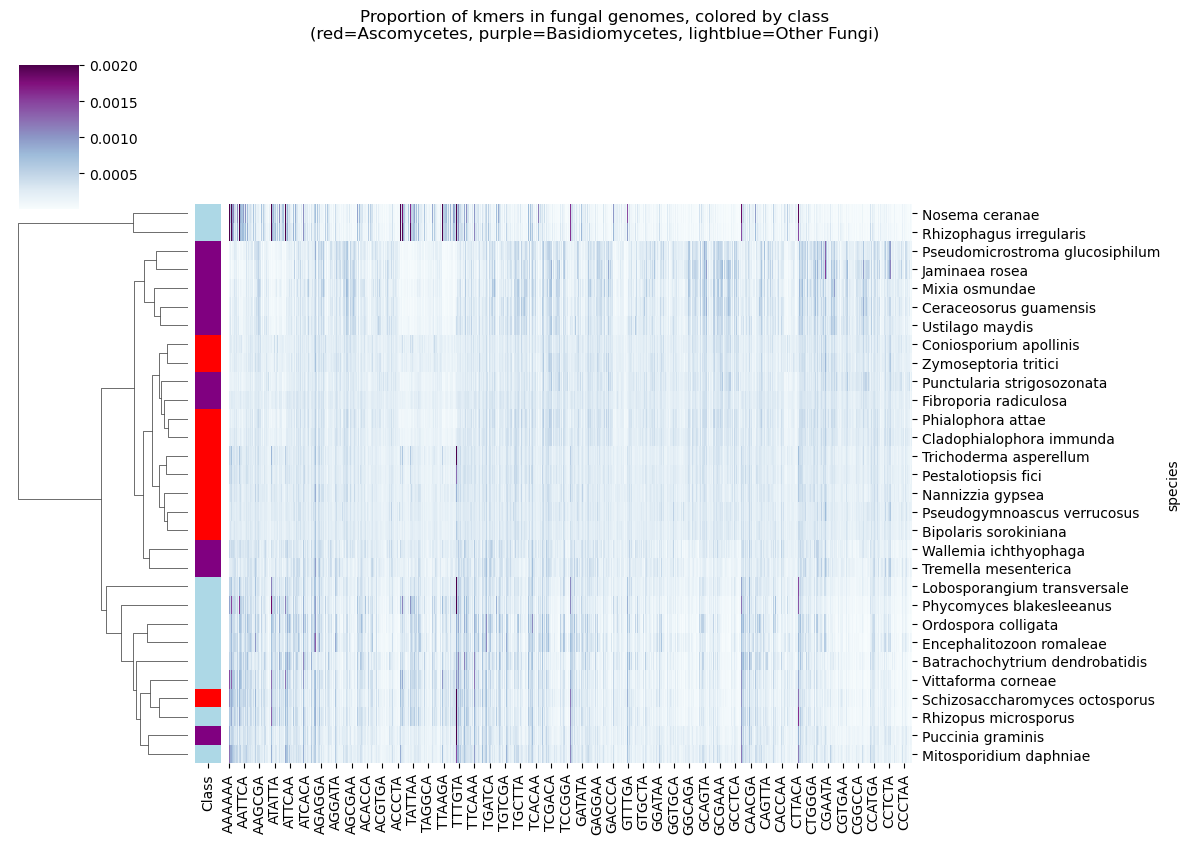

In [37]:
g = sns.clustermap(
    genomes.set_index("species").drop(columns=["Class"]),
    cmap="BuPu",
    vmax=0.002,
    col_cluster=False,
    figsize=(12, 8),
    row_colors=class_color,
)
g.fig.suptitle(
    "Proportion of kmers in fungal genomes, colored by class\n"
    "(red=Ascomycetes, purple=Basidiomycetes, lightblue=Other Fungi)",
    y=1.05,
);
